# 🧪 LAB: Implement an autoencoder with `PyTorch`

In this lab, you will implement and explore autoencoders using the MNIST dataset. The goal is to understand how autoencoders learn compressed representations of data, and how these representations compare with classical methods like PCA.

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = "Chloe Wang, Ethan Ooi, Namitha Tholasi"

## 1. Theoretical Background Reflection (10 points)

Read *Michelucci (2022)*: [An Introduction to Autoencoders](https://arxiv.org/abs/2201.03898) — focus on the following sections:  
- 1. Introduction
- 2.1, 2.2, and 2.3
- Skim Section 3 on applications  

Then answer briefly:

1. What is the main idea behind an autoencoder?  
2. What is the role of the bottleneck layer?  
3. Discuss, in your own words, the applications of autoencoders mentioned in the paper.  
4. What differences would you expect between an autoencoder’s representation and that of PCA if applied as a dimensionality reduction technique?


**1. What is the main idea behind an autoencoder?**

An autoencoder is basically a neural network that tries to rebuild its own input, so the input is also the target and we don't need any labels. The encoder squishes the input down into a smaller set of features, and then the decoder tries to rebuild the original input from just those features. The model has to learn the most important parts of the data to be able to rebuild it.

**2. What is the role of the bottleneck layer?**

The bottleneck is the middle layer, which has a lot less neurons than the input. Without it, the model could just learn to copy the input straight to the output and wouldn't be able to generalize new data & learn anything useful. We find a sweet spot with the number of important neurons to squeeze the input through, too little loses too much accuracy, and too many doesn't generalize well to new data. So it's forced to keep just the most important info needed to rebuild the input, which is what the autoencoder actually learns.

**3. Discuss, in your own words, the applications of autoencoders mentioned in the paper.**

The main one is dimensionality reduction, since the encoder by itself turns each observation into way less features. We can then use those features for classification, where in the paper kNN ran about 1000x faster on 8 latent features vs. all 784 pixels and only lost about 7% accuracy. It's also used in anomaly detection, like credit card fraud, and also for denoising, where the model learns to take a noisy image and give back the cleaned version.

**4. What differences would you expect between an autoencoder's representation and that of PCA if applied as a dimensionality reduction technique?**

PCA is linear, so it can only find straight line directions with the most variance, while an autoencoder with an activation layer, like ReLU, can pick up non-linear patterns. So with the same 2 dimensions, we'd expect the autoencoder to separate the digits better. But PCA is easier to interpret since the components are ordered by variance and it gives the same result every run, while the autoencoder's features are harder to interpret and can change depending on how it trains.

## 2. Prepare the Data (10 points)

Given the below dataset:

- Normalize **each** image (i.e., separately) so its values are between 0 and 1. Remember our first-week discussions of fixed and fitted transformations.
- Visualize a few random digits to confirm everything worked as expected.
- Split the dataset into fitting, tuning and reporting sets (70%, 15%, 15%).
- Wrap each data splitting as `DataLoader` object with a batch size of 128. Call them `fitting_loader`, `tuning_loader` and `reporting_loader`, respectively.

In [45]:
from sklearn.datasets import fetch_openml
mnist = fetch_openml("mnist_784", version=1, as_frame=False, n_retries=5, delay=2)
X, y = mnist.data, mnist.target.astype(int)

In [46]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

X = (X - X.min(axis=1, keepdims=True)) / (X.max(axis=1, keepdims=True) - X.min(axis=1, keepdims=True))

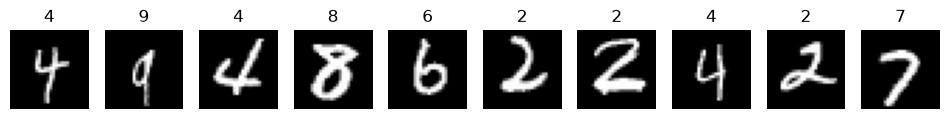

In [47]:
idx = np.random.choice(len(X), 10, replace=False)
fig, axis = plt.subplots(figsize=(12, 2), ncols=10)
for ax, i in zip(axis, idx):
    ax.imshow(X[i].reshape(28, 28), cmap="gray")
    ax.set_title(y[i])
    ax.axis("off")
plt.show()

In [48]:
X_fit, X_rest, y_fit, y_rest = train_test_split(X, y, test_size=0.3, random_state=1234, stratify=y)
X_tune, X_report, y_tune, y_report = train_test_split(X_rest, y_rest, test_size=0.5, random_state=1234, stratify=y_rest)

X_fit = torch.tensor(X_fit, dtype=torch.float32)
X_tune = torch.tensor(X_tune, dtype=torch.float32)
X_report = torch.tensor(X_report, dtype=torch.float32)

fitting_loader = DataLoader(TensorDataset(X_fit, torch.tensor(y_fit)), batch_size=128, shuffle=True)
tuning_loader = DataLoader(TensorDataset(X_tune, torch.tensor(y_tune)), batch_size=128)
reporting_loader = DataLoader(TensorDataset(X_report, torch.tensor(y_report)), batch_size=128)

## 3. Autoencoder

In this section, you will build and train an **autoencoder** to reconstruct the provided data.

Your model will include three layers in both the encoder and decoder:

- **Encoder:** 784 → 128 → 64 → 2. This last layer here is the **bottleneck**.
- **Decoder:** 2 → 64 → 128 → 784  

### 3.1 Implementation (30 points)

Follow the skeleton provided below and fill in the missing parts (`#TODO`). 

Follow these restrictions:

- Each **hidden** layer should include a linear transformation, ReLU activation function, dropout with `p=0.2` and batch normalization steps. Determine the appropriate order for these components based on what we discussed in class. The bottleneck layer is the exception; see next point.
- For the bottleneck, use only a linear transformation, i.e., no activation, batch normalization, or dropout.
- The output layer should have a sigmoid activation function.

In [49]:
import torch.nn as nn

class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        
        # ENCODING PART: 784 -> 128 -> 64 -> 2
        encoder_list = [
            nn.Linear(784, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(p=0.2),
            nn.Linear(128, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(p=0.2),
            nn.Linear(64, 2),
        ]
        self.encoder_list = nn.ModuleList(encoder_list)
        
        # DECODING PART: 2 -> 64 -> 128 -> 784
        decoder_list = [
            nn.Linear(2, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(p=0.2),
            nn.Linear(64, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(p=0.2),
            nn.Linear(128, 784), nn.Sigmoid(),
        ]
        self.decoder_list = nn.ModuleList(decoder_list)
        
    def forward(self, X):
        for layer in self.encoder_list:
            X = layer(X)
        for layer in self.decoder_list:
            X = layer(X)
        output = X
        return output


### 3.2 Training (15 points)

Follow the skeleton provided below and fill in the missing parts to train your model (`#TODO`). As you can see, training includes EarlyStopping, which I give you already for your convenience :-). After you have filled these missing parts, uncomment the provided piece of code with the function for training (`train_autoencoder`) your model and execute it.

But, **BEFORE** that, discuss with your mates and provide elaborated answers to the following:

- Why do you think the output layer of the autoencoder above uses a Sigmoid activation?
- Based on this, which cost function is most appropriate for this task? Justify your choice.

**1) We normalized every image so the pixels are between 0 and 1, and since the autoencoder is trying to rebuild that same image, the output needs to be between 0 and 1 too. Sigmoid squishes any number into that range.**

**2) We should used Mean Squared Error for this task, because it is a regression problem that we have to solve.**

Once you have discussed and agreed on the reasoning above, proceed to complete the skeleton (`#TODO`) and train the model.


In [50]:
torch.manual_seed(1234)

model = Autoencoder()

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)

In [51]:
class EarlyStopping:
    def __init__(self, patience=10, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False
        self.best_model_state = None

    def __call__(self, tuning_loss, model):
        if self.best_loss is None or tuning_loss < self.best_loss - self.min_delta:
            self.best_loss = tuning_loss
            self.counter = 0
            self.best_model_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True

    def restore_best_weights(self, model):
        if self.best_model_state is not None:
            model.load_state_dict(self.best_model_state)


def train_autoencoder(model, fitting_loader, tuning_loader, n_epochs=100, patience=5):
    # Initialize the early stopping object
    early_stopping = EarlyStopping(patience=patience)
    history = {"fitting": [], "tuning": []}

    for epoch in range(n_epochs):
        model.train()
        fitting_cost = 0.0

        for X_batch, _ in fitting_loader:
            # --- Implement the standard training steps ---
            
            outputs = model(X_batch)
            cost = criterion(outputs, X_batch)
            cost.backward()
            optimizer.step()
            optimizer.zero_grad()
            fitting_cost += cost.item() * X_batch.size(0)

        fitting_cost /= len(fitting_loader.dataset)

        # --- Tuning phase ---
        model.eval()
        tuning_cost = 0.0
        with torch.no_grad():
            for X_batch, _ in tuning_loader:
                outputs = model(X_batch)
                cost = criterion(outputs, X_batch)
                tuning_cost += cost.item() * X_batch.size(0)

        tuning_cost /= len(tuning_loader.dataset)

        # --- Save metrics ---
        history["fitting"].append(fitting_cost)
        history["tuning"].append(tuning_cost)

        print(f"Epoch [{epoch+1}/{n_epochs}]  Fitting Cost: {fitting_cost:.5f}  Tuning Cost: {tuning_cost:.5f}")

        # --- Early stopping check ---
        early_stopping(tuning_cost, model)
        if early_stopping.early_stop:
            print(f"Stopping early at epoch {epoch+1}")
            early_stopping.restore_best_weights(model)
            return model, history

    return model, history


Once the missing parts have been filled, uncomment the piece of code below and execute it to train your model (it may take a bit to complete the training, which is totally normal).

In [52]:
model, history = train_autoencoder(model, fitting_loader, tuning_loader, n_epochs=50, patience=5)

Epoch [1/50]  Fitting Cost: 0.06361  Tuning Cost: 0.04988
Epoch [2/50]  Fitting Cost: 0.05035  Tuning Cost: 0.04727
Epoch [3/50]  Fitting Cost: 0.04898  Tuning Cost: 0.04649
Epoch [4/50]  Fitting Cost: 0.04841  Tuning Cost: 0.04584
Epoch [5/50]  Fitting Cost: 0.04806  Tuning Cost: 0.04563
Epoch [6/50]  Fitting Cost: 0.04794  Tuning Cost: 0.04529
Epoch [7/50]  Fitting Cost: 0.04774  Tuning Cost: 0.04513
Epoch [8/50]  Fitting Cost: 0.04760  Tuning Cost: 0.04490
Epoch [9/50]  Fitting Cost: 0.04745  Tuning Cost: 0.04480
Epoch [10/50]  Fitting Cost: 0.04741  Tuning Cost: 0.04464
Epoch [11/50]  Fitting Cost: 0.04728  Tuning Cost: 0.04440
Epoch [12/50]  Fitting Cost: 0.04724  Tuning Cost: 0.04444
Epoch [13/50]  Fitting Cost: 0.04714  Tuning Cost: 0.04431
Epoch [14/50]  Fitting Cost: 0.04708  Tuning Cost: 0.04428
Epoch [15/50]  Fitting Cost: 0.04697  Tuning Cost: 0.04403
Epoch [16/50]  Fitting Cost: 0.04693  Tuning Cost: 0.04405
Epoch [17/50]  Fitting Cost: 0.04691  Tuning Cost: 0.04385
Epoch 

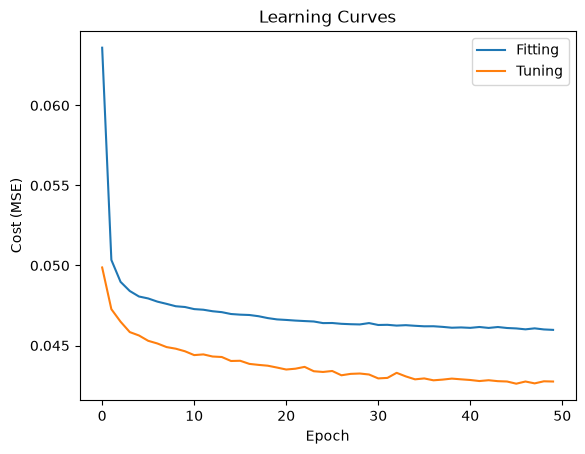

In [53]:
plt.plot(history["fitting"], label="Fitting")
plt.plot(history["tuning"], label="Tuning")
plt.xlabel("Epoch")
plt.ylabel("Cost (MSE)")
plt.title("Learning Curves")
plt.legend()
plt.show()

### 3.3 Reconstruct (5 points)

Once you have trained the model: 

1. Visualize several reconstructed digits from the reporting set.  
2. Compare them with the corresponding original input digits. Was the reconstruction good? 

**2) No, the reconstruction is poor. It is difficult to make out the digits. They are blurry, and several of them are classified as the wrong digits. We saw such common issues discussed in the reading, for example, where the digits 4 and 9 are typically confused or mixed up.**

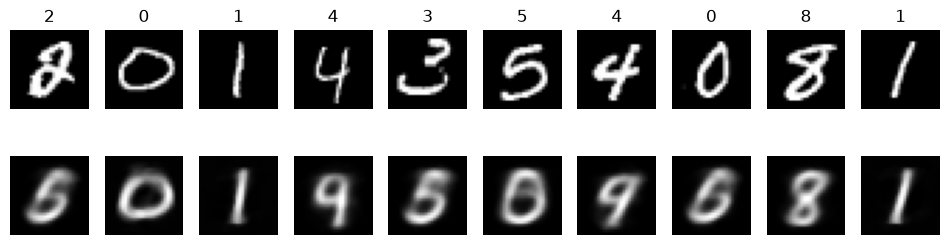

In [54]:
model.eval()
with torch.no_grad():
    reconstructed = model(X_report[:10])

fig, axis = plt.subplots(figsize=(12, 3), nrows=2, ncols=10)
for i in range(10):
    axis[0, i].imshow(X_report[i].reshape(28, 28), cmap="gray")
    axis[0, i].set_title(y_report[i])
    axis[0, i].axis("off")
    axis[1, i].imshow(reconstructed[i].reshape(28, 28), cmap="gray")
    axis[1, i].axis("off")
plt.show()

## 4. Visualize the Learned Representations (15 points)

Here you will explore the latent representations learned by your autoencoder.

1. Complete `extract_latent_features` to extract the latent (bottleneck) features and their corresponding labels, given a trained model.  
   Apply this function to the reporting set using the provided code. This should give you the transformed reporting set with the dimensions of the bottleneck (2).
2. Plot the reduced 2D data as a scatterplot, coloring each point by its corresponding digit label.


In [55]:
def extract_latent_features(model, dataloader): 
    model.eval()
    latents = []
    labels = []

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            
            encoded = X_batch
            for layer in model.encoder_list:
                encoded = layer(encoded)
            latents.append(encoded.numpy())
            labels.append(y_batch.numpy())

    # Concatenate all batches
    latents = np.concatenate(latents, axis=0)
    labels = np.concatenate(labels, axis=0)
    return latents, labels

Once the missing parts above have been filled, uncomment the piece of code below and execute it to extract the latent features

In [56]:
latents_autoencoder, labels = extract_latent_features(model, reporting_loader)

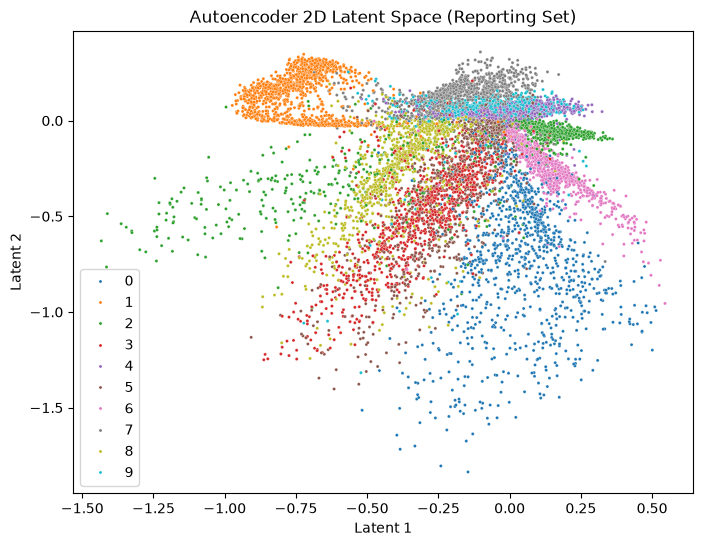

In [57]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=latents_autoencoder[:, 0], y=latents_autoencoder[:, 1], hue=labels, palette="tab10", s=5)
plt.xlabel("Latent 1")
plt.ylabel("Latent 2")
plt.title("Autoencoder 2D Latent Space (Reporting Set)")
plt.show()

## 5. Compare with PCA (10 points)

Here you will compare the latent representations learned by your autoencoder with those obtained using a PCA.

1. Apply a PCA to the reporting set (without using the autoencoder) to reduce the data to the same dimensionality as your bottleneck (2 dimensions). Obviously, first use the rest of the data to learn these two components.
2. Visualize the reduced 2D data as a scatterplot, coloring each point by its corresponding digit label.
3. Compare the structure of the two plots (Autoencoder vs. PCA) and briefly discuss the differences (if any) you observe.

The structure of the autoencoder has clear separation to each group. PCA is more scatter throughout and there is no clear grouping. This could be because PCA is linear so it cannot learn the non-linear patterns within this particular data set. For example, in the PCA plot, the scatter plot confuses 4, 7, and 9. However, in the autoencoder, the groups a little more fanned out with less overlap between each digit. Although 4, 7, and 9 are more clearly grouped, they are still in the same general area. 

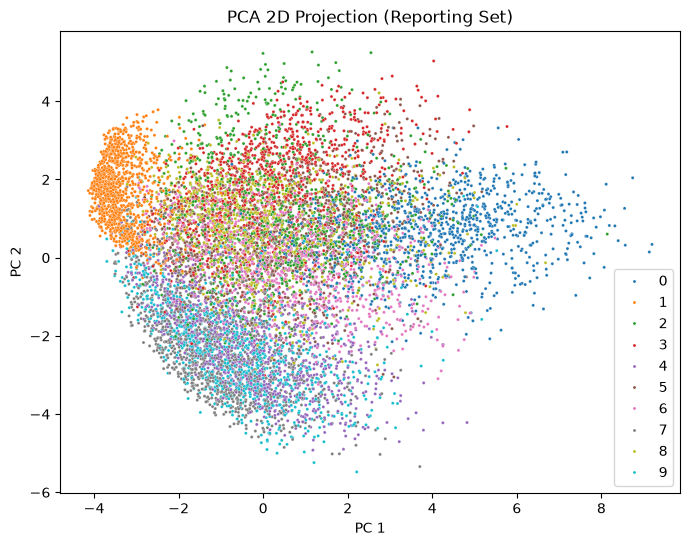

In [58]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca.fit(torch.cat([X_fit, X_tune]))
latents_pca = pca.transform(X_report)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=latents_pca[:, 0], y=latents_pca[:, 1], hue=labels, palette="tab10", s=5)
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.title("PCA 2D Projection (Reporting Set)")
plt.show()

## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.
**One aspect that can still be improved is collaborating on one computer and taking turns trying to understand the code when its their turn on the computer. One aspect that can be improved is preparedness. I think reading the paper takes a long time and understanding the material adds to the time spent not working on the actual lab. We plan to be better at reading the text before hand so we can understand the context of the lab tasks that we are working on.**